In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import FIG_DIR
import matplotlib.colors as mcolors
import numpy as np

from km5c.plotting import shade_below_bathymetry, temperatureadjustedplot
from km5c.models import load_hadcm3, load_icesm12, load_icesm13
from km5c.proxies import comparison_tables

hadcm3 = load_hadcm3()
hadcm3_Plio_d18O = hadcm3.Plio_d18O
hadcm3_Plio_depth = hadcm3.Plio_depth
hadcm3_Plio_lat = hadcm3.Plio_lat
hadcm3_Plio_lon = hadcm3.Plio_lon
hadcm3_Plio_temp = hadcm3.Plio_temp
hadcm3_preind_d18O = hadcm3.preind_d18O
hadcm3_preind_depth = hadcm3.preind_depth
hadcm3_preind_lat = hadcm3.preind_lat
hadcm3_preind_lon = hadcm3.preind_lon
hadcm3_preind_temp = hadcm3.preind_temp

icesm12 = load_icesm12()
Plio_d18O = icesm12.Plio_d18O
Plio_depth = icesm12.Plio_depth
Plio_lat = icesm12.Plio_lat
Plio_lon = icesm12.Plio_lon
Plio_temp = icesm12.Plio_temp
preind_d18O = icesm12.preind_d18O
preind_depth = icesm12.preind_depth
preind_lat = icesm12.preind_lat
preind_lon = icesm12.preind_lon
preind_temp = icesm12.preind_temp
preind_temp_lat = icesm12.preind_temp_lat
preind_temp_lon = icesm12.preind_temp_lon

icesm13 = load_icesm13()
icesm13_Plio_d18O = icesm13.Plio_d18O
icesm13_Plio_depth = icesm13.Plio_depth
icesm13_Plio_lat = icesm13.Plio_lat
icesm13_Plio_lon = icesm13.Plio_lon
icesm13_Plio_temp = icesm13.Plio_temp
icesm13_preind_d18O = icesm13.preind_d18O
icesm13_preind_depth = icesm13.preind_depth
icesm13_preind_lat = icesm13.preind_lat
icesm13_preind_lon = icesm13.preind_lon
icesm13_preind_temp = icesm13.preind_temp

proxy = comparison_tables()
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table

(1, 60, 180, 360)
(60, 180, 360)


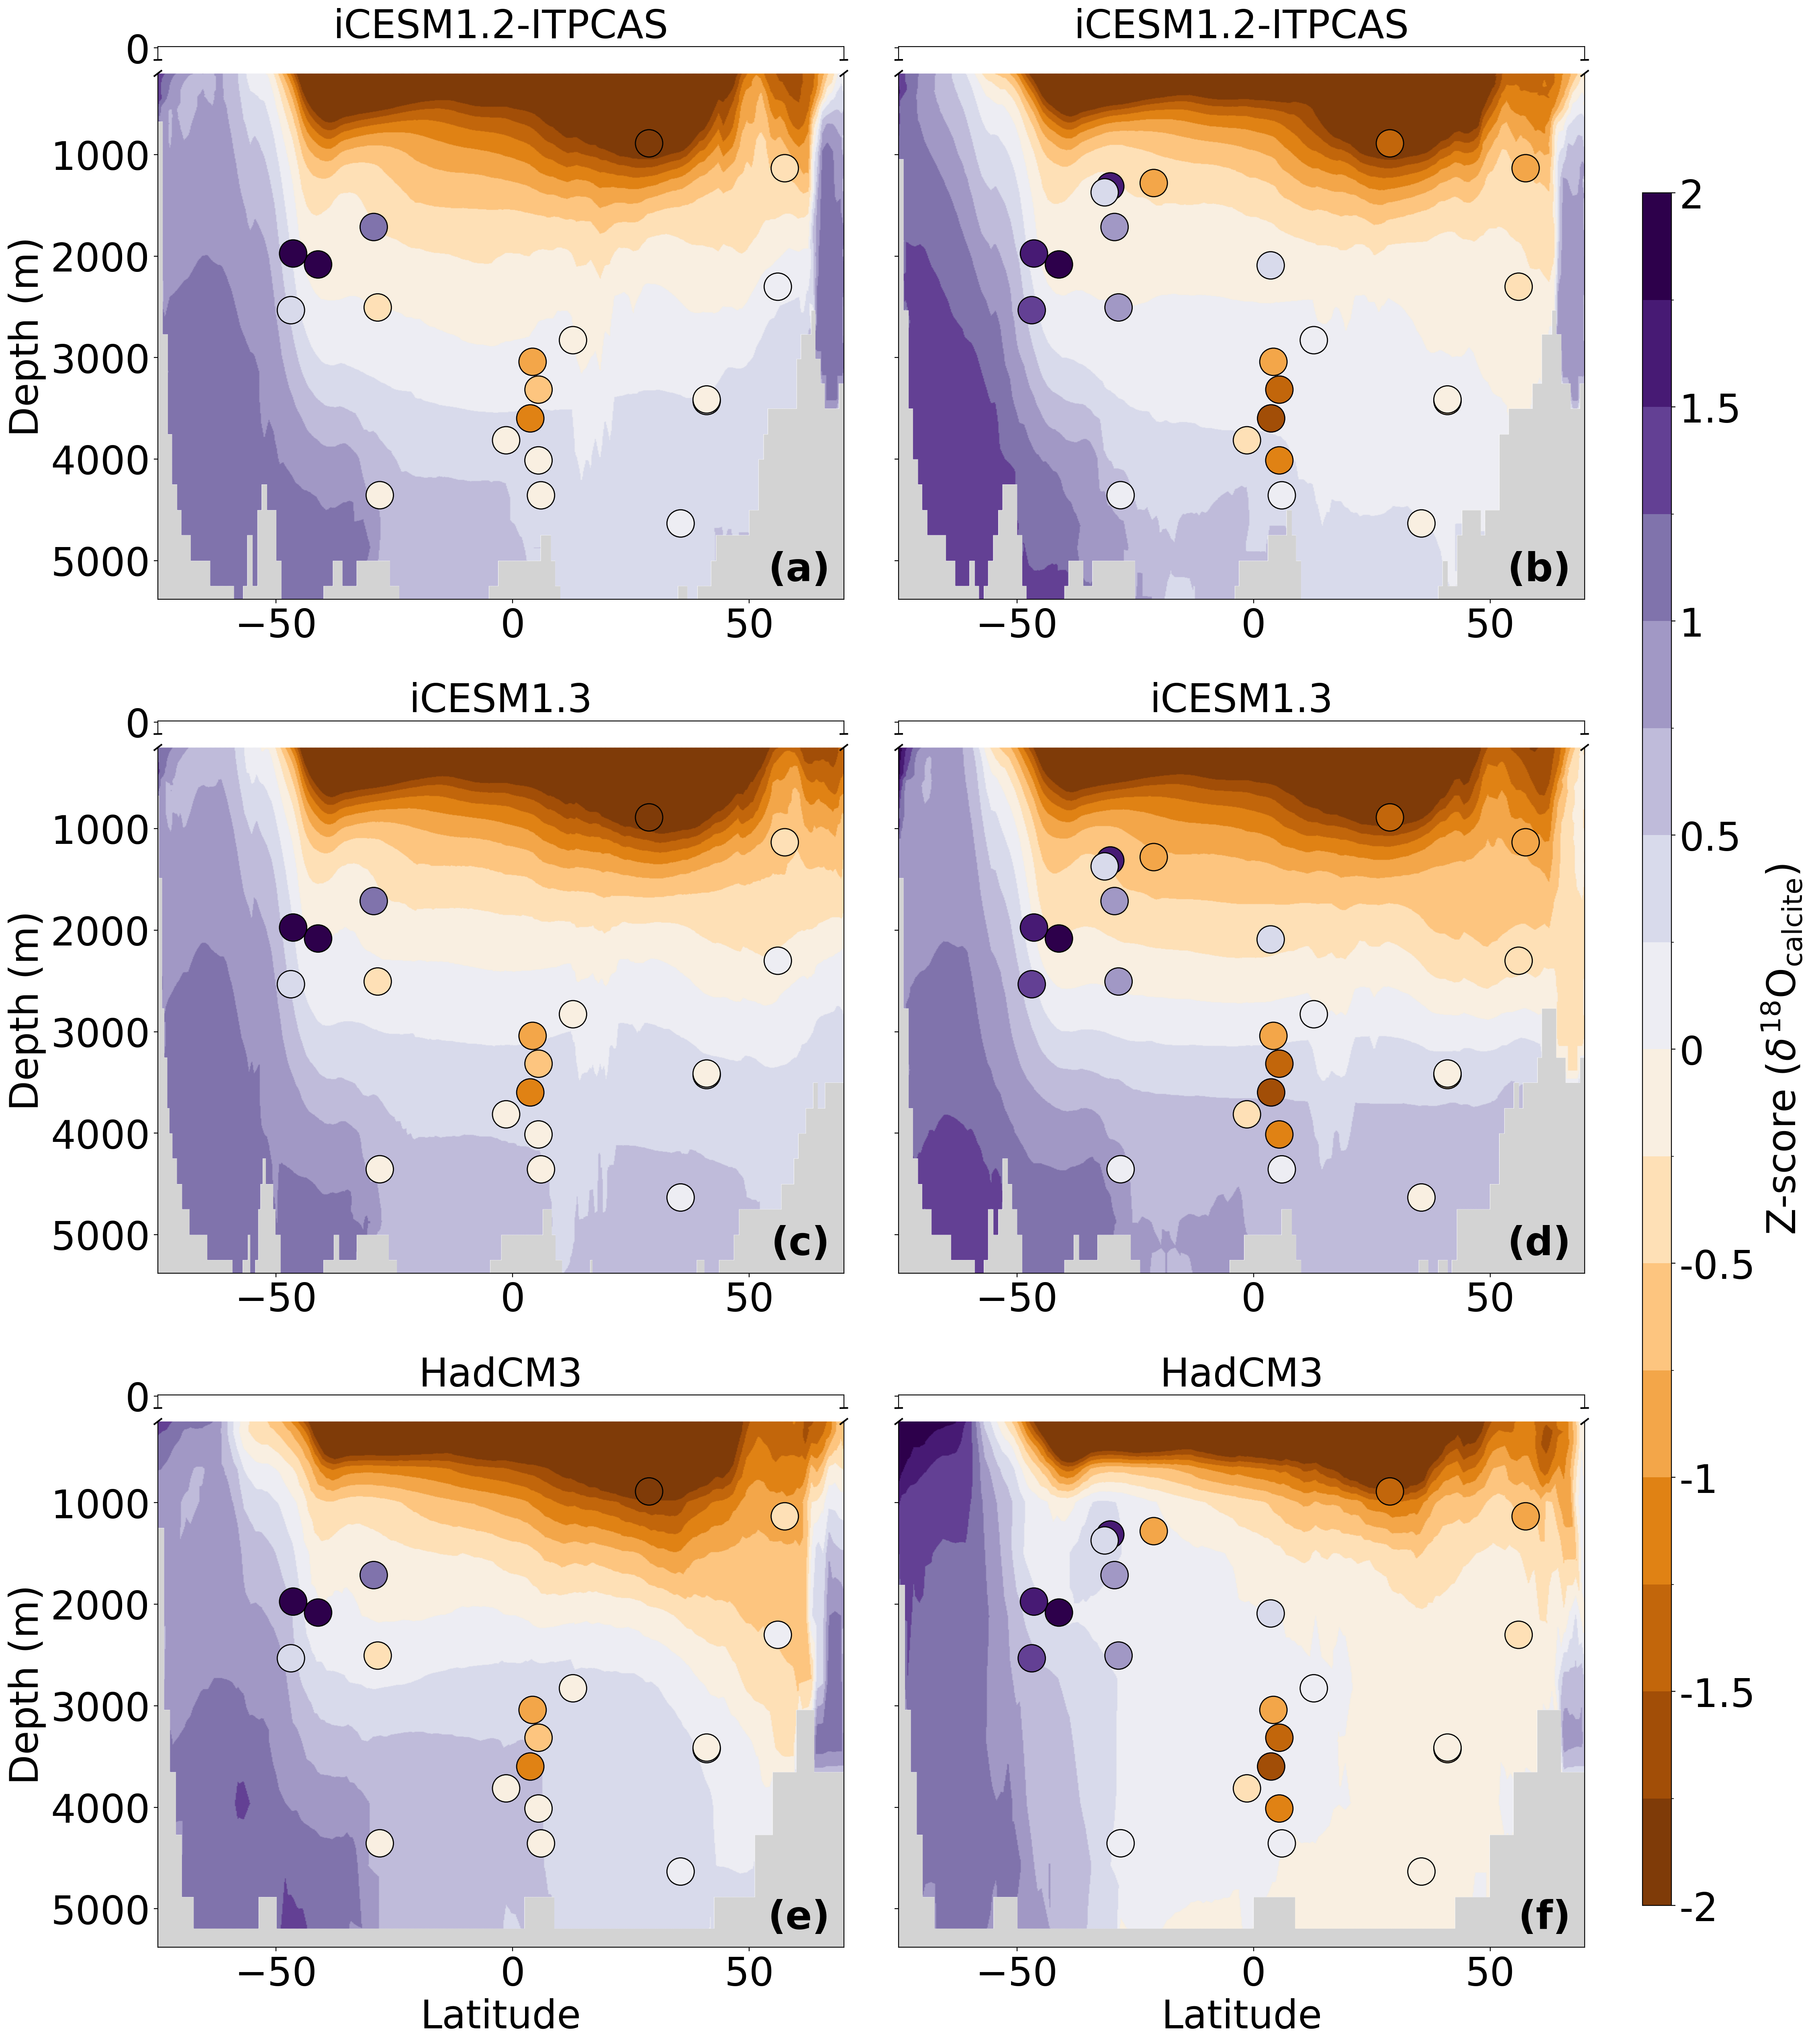

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
})

color_bins = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors = len(color_bins) - 1
colors = plt.cm.PuOr(np.linspace(0, 1, num_colors))
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=color_bins, ncolors=num_colors)

scatter_columns = ["OC3 d18O", "PLIOMIP2 d18O"]
scatter_norms = {}
for scatter_col in scatter_columns:
    values = PLIOMIP2_d18O_comparison_table[scatter_col]
    scatter_norms[scatter_col] = (values - np.nanmean(values)) / np.nanstd(values)

# Model display names (iCESM1.2-ITPCAS, iCESM1.3, HadCM3)
row_models = [
    {
        "name": "iCESM1.2-ITPCAS",
        "preind": dict(lat=preind_lat, lon=preind_lon, depth=preind_depth, field=preind_d18O, temp=preind_temp, mesh=True, samegrid=False, templat=preind_temp_lat, templon=preind_temp_lon, tempmesh=False),
        "plio": dict(lat=Plio_lat, lon=Plio_lon, depth=Plio_depth, field=Plio_d18O, temp=Plio_temp, mesh=False),
    },
    {
        "name": "iCESM1.3",
        "preind": dict(lat=icesm13_preind_lat, lon=icesm13_preind_lon, depth=icesm13_preind_depth, field=icesm13_preind_d18O, temp=icesm13_preind_temp, mesh=True),
        "plio": dict(lat=icesm13_Plio_lat, lon=icesm13_Plio_lon, depth=icesm13_Plio_depth, field=icesm13_Plio_d18O, temp=icesm13_Plio_temp, mesh=False),
    },
    {
        "name": "HadCM3",
        "preind": dict(lat=hadcm3_preind_lat, lon=hadcm3_preind_lon, depth=hadcm3_preind_depth, field=hadcm3_preind_d18O, temp=hadcm3_preind_temp, mesh=False),
        "plio": dict(lat=hadcm3_Plio_lat, lon=hadcm3_Plio_lon, depth=hadcm3_Plio_depth, field=hadcm3_Plio_d18O, temp=hadcm3_Plio_temp, mesh=False),
    },
]

panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

fig = plt.figure(figsize=(24, 26), dpi=200)
outer_grid = fig.add_gridspec(
    3, 2, hspace=0.22, wspace=0.08, left=0.1, right=0.84, top=0.97, bottom=0.06,
)
pc_for_cbar = None

for row, models in enumerate(row_models):
    for col, period in enumerate(["preind", "plio"]):
        model = models[period]
        # Convert model seawater d18O to the calcite quantity measured at the sites.
        testplot, lat, depth = temperatureadjustedplot(
            model["lat"], model["lon"], model["depth"], model["field"], model["temp"],
            mesh=model["mesh"],
            samegrid=model.get("samegrid", True),
            templat=model.get("templat"), templon=model.get("templon"),
            tempmesh=model.get("tempmesh", False),
            trimtop=True, normalise=False, top=200,
            mask=None, mask_lat=None, mask_lon=None,
        )

        plot_mean = np.nanmean(testplot)
        plot_std = np.nanstd(testplot)
        testplot = (testplot - plot_mean) / plot_std

        inner_grid = outer_grid[row, col].subgridspec(2, 1, height_ratios=[1, 40], hspace=0.05)
        ax1 = fig.add_subplot(inner_grid[0, 0])
        ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

        shade_below_bathymetry(ax1, lat, depth, testplot)
        ax1.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading="gouraud")
        ax1.set_title(models["name"], fontsize=35, pad=8)
        ax1.set_ylim(-1, 10)
        ax1.set_xlim([-75, 70])
        ax1.set_yticks([0])
        ax1.tick_params(bottom=False, labelbottom=False)
        if col == 1:
            ax1.tick_params(labelleft=False)

        shade_below_bathymetry(ax2, lat, depth, testplot)
        pc_for_cbar = ax2.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading="gouraud")
        ax2.set_ylim(200, 5380)
        ax2.set_xlim([-75, 70])
        if row == 2:
            ax2.set_xlabel("Latitude")
        if col == 0:
            ax2.set_ylabel("Depth (m)")
        else:
            ax2.tick_params(labelleft=False)

        ax1.invert_yaxis()
        ax2.invert_yaxis()
        ax1.spines["bottom"].set_visible(False)
        ax2.spines["top"].set_visible(False)

        scatter_col = scatter_columns[col]
        scatter_values = scatter_norms[scatter_col]
        ax2.scatter(
            PLIOMIP2_d18O_comparison_table["Latitude"],
            PLIOMIP2_d18O_comparison_table["Water depth (m)"],
            c=scatter_values,
            cmap=cmap, norm=norm,
            s=600,
            marker="o",
            edgecolors="black",
        )

        d = 0.005
        kwargs = dict(transform=ax1.transAxes, color="k", clip_on=False)
        ax1.plot((-d, +d), (-d, +d), **kwargs)
        ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
        kwargs.update(transform=ax2.transAxes)
        ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
        ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

        ax2.text(
            0.98, 0.02, panel_labels[row * 2 + col],
            transform=ax2.transAxes,
            ha="right", va="bottom",
            fontsize=35, fontweight="bold",
            zorder=20,
        )

cbar_ax = fig.add_axes([0.87, 0.08, 0.015, 0.82])
cbar = plt.colorbar(pc_for_cbar, cax=cbar_ax, boundaries=color_bins, ticks=color_bins[::2])
cbar.set_label(r"Z-score ($\delta^{18}\mathrm{O}_{\mathrm{calcite}}$)")
cbar.set_ticklabels([f"{t:g}" for t in color_bins[::2]])

fig.savefig(FIG_DIR / "d18O_lat_depth.png", dpi=300, bbox_inches="tight")
plt.show()
